# 07 · Validación e interpretación — abrir la prueba, una sola vez

> **BORRADOR para revisión del grupo.** Guía: `material-del-curso/kit/guia-validacion-registro-y-app.md`, secciones 1 a 4. Modelo: **sin `Policy_Sales_Channel` y con `Gender`** (decisiones D12 y D13).

Hasta aquí **nadie ha mirado el conjunto de prueba**. Hoy se abre, y las reglas son estrictas:

1. Todas las decisiones (modelo, parámetros, calibración) se toman **antes** y se **escriben**; solo con entrenamiento.
2. La prueba se evalúa **una vez**. Si algo no gusta, no se "ajusta y se vuelve a mirar".
3. No basta un número: se pide el **intervalo** (remuestreando clientes), la **comparación con el baseline**, el **error por segmento** y **por qué** decide así el modelo.

## 0. Cargar los datos de entrenamiento

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve()
ROOT = ROOT if (ROOT / "src").exists() else ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import brier_score_loss, log_loss
from sklearn.model_selection import train_test_split

from proyecto.data.loading import load_train
from proyecto.models.baselines import DamageRuleClassifier
from proyecto.models.metrics import audit_by_group, decision_threshold, technical_metrics
from proyecto.models.tuning import START_PARAMS, bootstrap_interval, build_tuned_pipeline, per_client_cost

ID_COL, TARGET = "id", "Response"
BLUE, ORANGE, GRAY, INK = "#2F6FB5", "#D9822B", "#8A8A8A", "#222222"
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#cccccc",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#eeeeee",
                     "axes.axisbelow": True, "font.size": 10, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left", "figure.dpi": 110})

train = load_train(ROOT)                       # solo entrenamiento: la prueba cerrada NO se carga todavía
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET]
print(f"entrenamiento: {train.shape[0]:,} filas x {train.shape[1]} columnas; tasa de aceptación {y_train.mean():.3%}")
print("¿Existe ya la marca de apertura de la prueba?", (ROOT / "reports" / "prueba_abierta.txt").exists())

entrenamiento: 304,887 filas x 12 columnas; tasa de aceptación 12.256%
¿Existe ya la marca de apertura de la prueba? True


## 1. Calibración — con clientes reservados del entrenamiento, **no** con la prueba

La decisión se toma con un umbral de probabilidad (16,7 %), así que importa que la probabilidad sea fiel. Se reserva un 25 % de los **clientes** (un cliente por fila, `id` único), se ajusta LightGBM con el 75 % y se compara en el 25 % la probabilidad **sin calibrar** con la **calibrada** (regresión isotónica).

In [2]:
Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.25, stratify=y_train, random_state=11)
base_model = build_tuned_pipeline("lightgbm", START_PARAMS["lightgbm"])
raw = clone(base_model).fit(Xa, ya)
calibrated = CalibratedClassifierCV(clone(base_model), method="isotonic", cv=3).fit(Xa, ya)

def max_decile_gap(y_true, proba, bins=10):
    t = pd.DataFrame({"y": np.asarray(y_true), "p": np.asarray(proba)})
    t["g"] = pd.qcut(t["p"].rank(method="first"), bins, labels=False)
    g = t.groupby("g").agg(real=("y", "mean"), pred=("p", "mean"))
    return float((g["real"] - g["pred"]).abs().max())

rows = {}
for name, model in {"sin calibrar": raw, "calibrado (isotónica)": calibrated}.items():
    p = model.predict_proba(Xb)[:, 1]
    rows[name] = {"log loss": log_loss(yb, p), "Brier": brier_score_loss(yb, p),
                  "mayor diferencia predicha-real en un decil": max_decile_gap(yb, p),
                  "costo por cliente": float(per_client_cost(yb, p).mean())}
calib_table = pd.DataFrame(rows).T
display(calib_table.style.format("{:.4f}"))

gain_logloss = rows["sin calibrar"]["log loss"] - rows["calibrado (isotónica)"]["log loss"]
gain_cost = rows["sin calibrar"]["costo por cliente"] - rows["calibrado (isotónica)"]["costo por cliente"]
CALIBRAR = bool(gain_logloss > 0.001 and gain_cost > 0.001)
print(f"Mejora del log loss al calibrar: {gain_logloss:+.5f}; del costo: {gain_cost:+.5f} -> calibrar = {CALIBRAR}")

,log loss,Brier,mayor diferencia predicha-real en un decil,costo por cliente
sin calibrar,0.2672,0.0874,0.0079,0.3293
calibrado (isotónica),0.2672,0.0874,0.0164,0.3292


Mejora del log loss al calibrar: -0.00005; del costo: +0.00018 -> calibrar = False


## 2. Decisiones congeladas — **antes** de abrir la prueba

Se escriben y se guardan con la hora, **antes** de cargar la prueba. Son lo que se defenderá ante el instructor; si se cambia algo después de ver la prueba, hay que declararlo en el reporte.

In [3]:
DECISIONES = {
    "modelo_final": "LightGBM",                      # D10: principal; la regresión queda como alternativa explicable
    "parametros": "partida",                         # etapa 6: la optimización no fue demostrablemente mejor
    "parametros_valores": START_PARAMS["lightgbm"],
    "variables": "sin Policy_Sales_Channel (D13), sin Vintage ni Driving_License, con Gender (D12)",
    "calibrar": CALIBRAR,                            # decidido con clientes reservados del entrenamiento (sección 1)
    "metrica_principal": "costo esperado por cliente (R = 5)",
    "regla_de_decision": f"llamar si P(compra) > 1/(R+1) = {decision_threshold():.4f}",
    "decidido_el": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
faltan = [k for k, v in DECISIONES.items() if v is None]
assert not faltan, f"faltan decisiones: {faltan}"
(ROOT / "reports").mkdir(exist_ok=True)
frozen = ROOT / "reports" / "07_decisiones_congeladas.json"
if not frozen.exists():
    frozen.write_text(json.dumps(DECISIONES, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(json.loads(frozen.read_text(encoding="utf-8")), indent=2, ensure_ascii=False))

{
  "modelo_final": "LightGBM",
  "parametros": "partida",
  "parametros_valores": {
    "n_estimators": 200,
    "learning_rate": 0.08,
    "num_leaves": 31,
    "min_child_samples": 100,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 0.0
  },
  "variables": "sin Policy_Sales_Channel (D13), sin Vintage ni Driving_License, con Gender (D12)",
  "calibrar": false,
  "metrica_principal": "costo esperado por cliente (R = 5)",
  "regla_de_decision": "llamar si P(compra) > 1/(R+1) = 0.1667",
  "decidido_el": "2026-11-05 19:09"
}


## 3. Entrenar el modelo final con **todo** el entrenamiento

El modelo final se entrena con el 100 % del entrenamiento y se guarda **entero** (preprocesamiento + modelo) para registrarlo en el notebook 08. También se ajustan las dos referencias: la regla "llamar si hubo daño" (baseline) y la regresión logística (alternativa explicable).

In [4]:
final_base = build_tuned_pipeline("lightgbm", DECISIONES["parametros_valores"])
modelo_final = CalibratedClassifierCV(final_base, method="isotonic", cv=3) if DECISIONES["calibrar"] else clone(final_base)
modelo_final.fit(X_train, y_train)

baseline = DamageRuleClassifier().fit(X_train, y_train)
alternativa = build_tuned_pipeline("regresion_logistica", START_PARAMS["regresion_logistica"]).fit(X_train, y_train)

(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(modelo_final, ROOT / "models" / "final_pipeline.joblib")
print("modelo final guardado en models/final_pipeline.joblib")

modelo final guardado en models/final_pipeline.joblib


## 4. Abrir la prueba — **una sola vez**

A partir de aquí **no se cambia nada del modelo**. Esta sección deja una marca (`reports/prueba_abierta.txt`) para que quede constancia de cuándo se abrió.

In [5]:
marca = ROOT / "reports" / "prueba_abierta.txt"
if marca.exists():
    print("AVISO:", marca.read_text(encoding="utf-8").strip())
    print("Si abres la prueba otra vez para decidir algo, deja de medir generalización: decláralo en el reporte.")
else:
    marca.write_text(f"La prueba se abrió por primera vez el {datetime.now():%Y-%m-%d %H:%M}.", encoding="utf-8")
test = pd.read_parquet(ROOT / "data" / "processed" / "holdout.parquet")
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET]
print(f"prueba: {test.shape[0]:,} filas (primera y única evaluación); tasa de aceptación {y_test.mean():.3%}")

AVISO: La prueba se abrió por primera vez el 2026-11-05 19:09.
Si abres la prueba otra vez para decidir algo, deja de medir generalización: decláralo en el reporte.
prueba: 76,222 filas (primera y única evaluación); tasa de aceptación 12.256%


In [6]:
proba_final = modelo_final.predict_proba(X_test)[:, 1]
proba_base = baseline.predict_proba(X_test)[:, 1]
proba_alt = alternativa.predict_proba(X_test)[:, 1]

metricas_prueba = {}
for name, p in {"modelo final (LightGBM)": proba_final, "baseline: llamar si hubo daño": proba_base, "alternativa: regresión logística": proba_alt}.items():
    metricas_prueba[name] = technical_metrics(y_test, p)
resumen = pd.DataFrame(metricas_prueba).T
cols = ["cost", "cost_top", "pr_auc", "roc_auc", "recall_top", "precision_1", "recall_1", "contact_rate", "log_loss", "brier"]
display(resumen[cols].style.format("{:.4f}"))

,cost,cost_top,pr_auc,roc_auc,recall_top,precision_1,recall_1,contact_rate,log_loss,brier
modelo final (LightGBM),0.3317,0.3988,0.3533,0.8519,0.5630,0.2960,0.8750,0.3623,0.2672,0.0875
baseline: llamar si hubo daño,0.3967,0.5229,0.2357,0.7709,0.3942,0.2381,0.9799,0.5045,0.2924,0.0940
alternativa: regresión logística,0.3349,0.4040,0.3437,0.8485,0.5560,0.2935,0.8749,0.3654,0.2690,0.0880


## 5. Intervalo y comparación con el baseline — remuestreando **clientes**

Un número sin intervalo no dice cuánto confiar. Se remuestrean clientes completos (aquí un cliente es una fila, `id` único). La diferencia se calcula cliente por cliente: **negativo = el modelo cuesta menos**.

In [7]:
costo_final = per_client_cost(y_test, proba_final)
costo_base = per_client_cost(y_test, proba_base)
costo_alt = per_client_cost(y_test, proba_alt)
ids = test[ID_COL].to_numpy()

def media_con_intervalo(valores):
    low, high = bootstrap_interval(valores - valores.mean(), ids)       # intervalo de la media = media + [bajo, alto] del centrado
    return float(valores.mean()), float(valores.mean() + low), float(valores.mean() + high)

filas = {
    "modelo final (LightGBM)": media_con_intervalo(costo_final),
    "baseline: llamar si hubo daño": media_con_intervalo(costo_base),
    "alternativa: regresión logística": media_con_intervalo(costo_alt),
}
tabla_costos = pd.DataFrame(filas, index=["costo por cliente", "intervalo 95 % (bajo)", "intervalo 95 % (alto)"]).T
display(tabla_costos.style.format("{:.4f}"))

dif_base = bootstrap_interval(costo_final - costo_base, ids)
dif_alt = bootstrap_interval(costo_final - costo_alt, ids)
print(f"Modelo menos baseline: {np.mean(costo_final - costo_base):+.4f} por cliente, intervalo 95 % [{dif_base[0]:+.4f}, {dif_base[1]:+.4f}] "
      f"(≈ {-np.mean(costo_final - costo_base) * 100_000:,.0f} unidades de llamada ahorradas por 100.000 clientes).")
print(f"Modelo menos regresión: {np.mean(costo_final - costo_alt):+.4f} por cliente, intervalo 95 % [{dif_alt[0]:+.4f}, {dif_alt[1]:+.4f}].")
print("¿Todo el intervalo contra el baseline queda por debajo de cero?", dif_base[1] < 0)

,costo por cliente,intervalo 95 % (bajo),intervalo 95 % (alto)
modelo final (LightGBM),0.3317,0.3264,0.3369
baseline: llamar si hubo daño,0.3967,0.3927,0.4006
alternativa: regresión logística,0.3349,0.3298,0.3402


Modelo menos baseline: -0.0650 por cliente, intervalo 95 % [-0.0700, -0.0607] (≈ 6,503 unidades de llamada ahorradas por 100.000 clientes).
Modelo menos regresión: -0.0031 por cliente, intervalo 95 % [-0.0060, -0.0006].
¿Todo el intervalo contra el baseline queda por debajo de cero? True


## 6. Errores por segmento y carga de trabajo

Un buen promedio puede esconder un grupo al que el modelo le va mal. Se mira por **género** y por **tramo de edad** (la vista previa de la etapa 5, ahora con la prueba cerrada). Y la **carga de trabajo**: cuántos clientes marca el modelo frente a cuántos compran de verdad.

In [8]:
audit = test[["Gender", "Age"]].copy()
audit["tramo de edad"] = pd.cut(audit["Age"], [19, 25, 35, 45, 55, 65, 90], labels=["20-25", "26-35", "36-45", "46-55", "56-65", "66+"])
LABELS = {"clients": "clientes", "real_rate": "tasa real", "called_rate": "% llamados", "recall": "recall (compradores llamados)",
          "precision": "precisión (llamados que compran)", "buyers_missed": "compradores no llamados"}
fmt = {"clientes": "{:,.0f}", "tasa real": "{:.1%}", "% llamados": "{:.1%}", "recall (compradores llamados)": "{:.1%}",
       "precisión (llamados que compran)": "{:.1%}", "compradores no llamados": "{:,.0f}"}

def audit_by(column):
    return audit_by_group(y_test, proba_final, audit[column]).rename(columns=LABELS)

por_genero, por_edad = audit_by("Gender"), audit_by("tramo de edad")
print("Por género (el modelo SÍ usa el género):")
display(por_genero.style.format(fmt))
print("Por tramo de edad:")
display(por_edad.style.format(fmt))

llamados = float((proba_final >= decision_threshold()).mean())
print(f"Carga de trabajo: el modelo marca al {llamados:.1%} de los clientes; en realidad compra el {y_test.mean():.1%} "
      f"(≈ {llamados / y_test.mean():.1f} llamadas por cada comprador real).")

Por género (el modelo SÍ usa el género):


,clientes,tasa real,% llamados,recall (compradores llamados),precisión (llamados que compran),compradores no llamados
Gender,,,,,,
Female,"34,913",10.2%,29.6%,84.5%,29.2%,552
Male,"41,309",14.0%,41.8%,89.3%,29.9%,616


Por tramo de edad:


,clientes,tasa real,% llamados,recall (compradores llamados),precisión (llamados que compran),compradores no llamados
tramo de edad,,,,,,
20-25,"22,838",3.6%,5.7%,33.3%,20.6%,542
26-35,"14,595",11.2%,31.0%,91.8%,33.2%,135
36-45,"14,118",21.7%,65.5%,98.1%,32.5%,59
46-55,"12,299",19.4%,64.9%,98.1%,29.4%,45
56-65,"6,772",14.6%,56.1%,92.8%,24.1%,71
66+,"5,600",8.1%,13.6%,30.4%,18.1%,316


Carga de trabajo: el modelo marca al 36.2% de los clientes; en realidad compra el 12.3% (≈ 3.0 llamadas por cada comprador real).


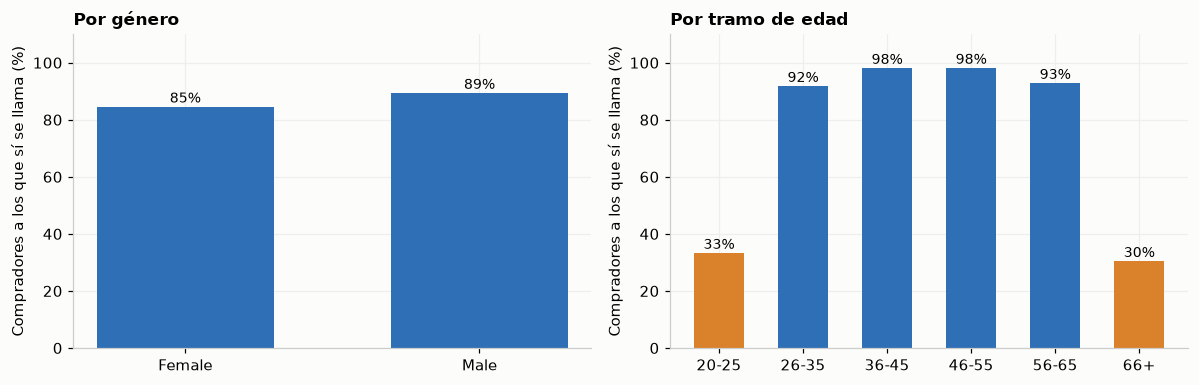

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (tabla, titulo) in zip(axes, [(por_genero, "Por género"), (por_edad, "Por tramo de edad")]):
    r = tabla["recall (compradores llamados)"] * 100
    ax.bar([str(i) for i in r.index], r.to_numpy(), color=[ORANGE if v < 60 else BLUE for v in r], width=0.6)
    for i, v in enumerate(r):
        ax.text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
    ax.set_ylim(0, 110)
    ax.set_ylabel("Compradores a los que sí se llama (%)")
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

## 7. ¿Por qué decide así el modelo? (SHAP)

Los valores SHAP muestran qué variables mueven la predicción. Límite: **explican al modelo, no al mundo**, y las variables correlacionadas se reparten el crédito. Se calculan sobre una muestra de la prueba **sin cambiar nada del modelo**.

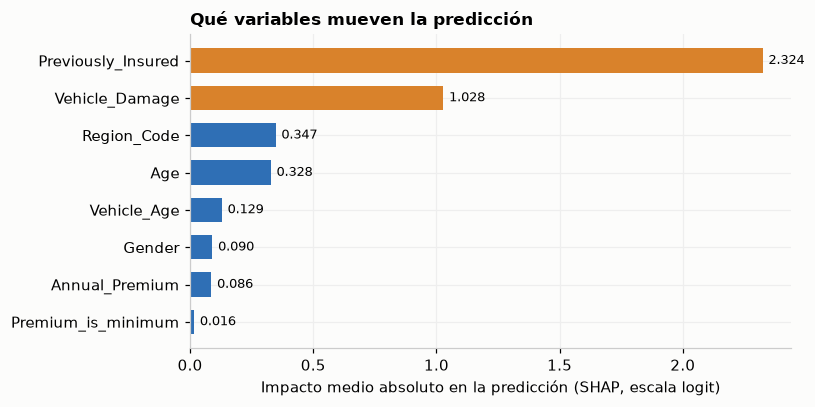

Orden de importancia: [('Previously_Insured', 2.324), ('Vehicle_Damage', 1.028), ('Region_Code', 0.347), ('Age', 0.328), ('Vehicle_Age', 0.129), ('Gender', 0.09), ('Annual_Premium', 0.086), ('Premium_is_minimum', 0.016)]


In [10]:
import shap

lgbm_pipeline = modelo_final.calibrated_classifiers_[0].estimator if DECISIONES["calibrar"] else modelo_final
features = lgbm_pipeline.named_steps["features"]
booster = lgbm_pipeline.named_steps["model"]
names = list(features.get_feature_names_out())

sample = X_test.sample(4000, random_state=0)
Z = features.transform(sample)
Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
explainer = shap.TreeExplainer(booster)
sv = explainer.shap_values(Z)
sv = sv[1] if isinstance(sv, list) else sv
sv = np.asarray(sv)
if sv.ndim == 3:
    sv = sv[:, :, 1]

# se agrupan las columnas de una misma variable original (por ejemplo, todas las regiones)
def original(name):
    for base in ("Region_Code", "Gender"):
        if name.startswith(base):
            return base
    return name

imp = pd.Series(np.abs(sv).mean(axis=0), index=names).groupby(original).sum().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(imp.index, imp.to_numpy(), color=[ORANGE if v > imp.max() * 0.15 else BLUE for v in imp], height=0.65)
for i, v in enumerate(imp):
    ax.text(v + imp.max() * 0.01, i, f"{v:.3f}", va="center", fontsize=8.5)
ax.set_xlabel("Impacto medio absoluto en la predicción (SHAP, escala logit)")
ax.set_title("Qué variables mueven la predicción")
plt.tight_layout()
plt.show()
print("Orden de importancia:", list(imp.sort_values(ascending=False).round(3).items()))

In [11]:
# Dos clientes concretos: uno al que se llama y compra, y uno al que no se llama
p_sample = pd.Series(modelo_final.predict_proba(sample)[:, 1], index=sample.index)
y_sample = y_test.loc[sample.index]
called_buyer = p_sample[(y_sample == 1) & (p_sample >= decision_threshold())].sort_values(ascending=False).index[0]
not_called = p_sample[p_sample < decision_threshold()].sort_values().index[0]
pos = {idx: k for k, idx in enumerate(sample.index)}
for titulo, idx in [("Cliente al que se llama y compra", called_buyer), ("Cliente al que NO se llama", not_called)]:
    contrib = pd.Series(sv[pos[idx]], index=names).groupby(original).sum().sort_values(key=np.abs, ascending=False).head(4)
    print(f"{titulo}: P(compra) = {p_sample[idx]:.1%}")
    print(sample.loc[idx, ["Age", "Gender", "Previously_Insured", "Vehicle_Damage", "Vehicle_Age", "Region_Code"]].to_dict())
    print("  qué más empuja la predicción:", {k: round(float(v), 2) for k, v in contrib.items()}, "\n")

Cliente al que se llama y compra: P(compra) = 52.0%
{'Age': 31, 'Gender': 'Male', 'Previously_Insured': 0, 'Vehicle_Damage': 1, 'Vehicle_Age': 1, 'Region_Code': 3}
  qué más empuja la predicción: {'Previously_Insured': 1.96, 'Vehicle_Damage': 1.13, 'Age': 0.67, 'Region_Code': 0.29} 

Cliente al que NO se llama: P(compra) = 0.0%
{'Age': 79, 'Gender': 'Female', 'Previously_Insured': 1, 'Vehicle_Damage': 0, 'Vehicle_Age': 1, 'Region_Code': 48}
  qué más empuja la predicción: {'Previously_Insured': -2.62, 'Age': -0.92, 'Vehicle_Damage': -0.88, 'Region_Code': -0.27} 



## 8. Guardar los resultados de la etapa

In [12]:
def limpio(obj):
    if isinstance(obj, dict):
        return {k: limpio(v) for k, v in obj.items()}
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    return obj

resultados = {
    "decisiones": DECISIONES,
    "prueba": {
        "clientes": int(len(test)),
        "abierta_el": marca.read_text(encoding="utf-8").strip(),
        "metricas": limpio(metricas_prueba),
        "costo_por_cliente": {k: {"media": v[0], "ic95_bajo": v[1], "ic95_alto": v[2]} for k, v in filas.items()},
        "modelo_menos_baseline": {"media": float(np.mean(costo_final - costo_base)), "ic95": list(dif_base)},
        "modelo_menos_regresion": {"media": float(np.mean(costo_final - costo_alt)), "ic95": list(dif_alt)},
        "porcentaje_llamado": llamados,
    },
    "segmentos": {"genero": por_genero.reset_index().to_dict("records"),
                  "edad": por_edad.reset_index().astype({"tramo de edad": str}).to_dict("records")},
    "shap_importancia": {k: float(v) for k, v in imp.sort_values(ascending=False).items()},
}
destino = ROOT / "reports" / "07_metricas_test.json"
destino.write_text(json.dumps(limpio(resultados), indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("guardado:", destino.name)

guardado: 07_metricas_test.json


## Entregable de esta etapa

- [x] Decisiones congeladas **antes** de abrir la prueba (`reports/07_decisiones_congeladas.json`, con fecha y hora).
- [x] Calibración decidida con clientes reservados del entrenamiento, no con la prueba.
- [x] Prueba abierta **una sola vez** (marca en `reports/prueba_abierta.txt`).
- [x] Intervalo del 95 % remuestreando clientes y comparación con el baseline.
- [x] Errores por segmento (género y edad) y carga de trabajo.
- [x] Interpretación con SHAP.
- [ ] Completar `reports/07_validacion.md` con lo que se leyó aquí.
- [ ] Legal revisa el uso de `Gender` y el grupo decide el piso de contacto para 20-25 y 66+.

**Siguiente:** `08_registro_modelo.ipynb`.